# 1. Libraries

In [46]:
# Import pandas
import pandas as pd

# Import numpy
import numpy as np

# Import seaborn for plotting
import seaborn as sns

# Set style of seaborn library 
sns.set_style("darkgrid")

# Import matplotlib for plotting
from matplotlib import pyplot as plt

# 2. Modules

In [47]:
from data_module import *

from evaluation_module import *

from non_linear_module import *

# 3. Raw Data

### 3.1 Specification

In [48]:
# Specify time period 
Start = "01/31/1986" 
End = "12/31/2018" 

# Define feature variables 
Features_v = ["Momentum_12_1M", "BookToPrice", "Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
              "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
              "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
              "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

# Define return variable 
Return_v = "TotalReturnUSD"

# Define market size variable 
Size_v = "Mcap_BMI_USD"

# Specify method (rolling or expanding)
Method = "rolling"  

# Specify after how many month the model is refitted 
Refit = 12

# Specify years of rolling window/min years of expanding method
Years = 10

# Specify number of portfolios for backtesting
N = 10

# Specify validation method: walk-forward (wf) or blocking walk-forward (bwf)
Validation = "wf"

# Specify the years used for validation.
Val_size=1

# Specify number of splits for validation
N_splits=3

### 3.2 Import 

In [49]:
# Import data 
Features, Return, Response, Size = import_data(Features=Features_v, 
                                               Return=Return_v, 
                                               Size=Size_v, 
                                               Start=Start, 
                                               End=End)

# 4. Data Processing

### 4.1 Take log of Size feature

In [50]:
# Take log of size variable
Features.loc[:,"Mcap_BMI_USD"] = Features.loc[:,"Mcap_BMI_USD"].apply(np.log)

# Rename column
Features.rename(columns={"Mcap_BMI_USD":"log_Mcap_BMI_USD"}, inplace=True)

### 4.2 Concat Data and drop NAs

In [51]:
# Concat variables
Data = pd.concat([Features, Return, Response, Size], axis=1)

# Drop inf and NAs
Data = Data.replace([np.inf, -np.inf], np.nan).dropna(how="any")

### 4.3 Winsorize features

In [52]:
# Winsorize features 
Data = winsorize_panel(Panel_Data=Data, 
                       Features=Features.columns, 
                       Upper=0.01, 
                       Lower=0.01)

### 4.4 Show Statistics

In [53]:
# Compute statistics
Data_stats = stats_panel(Panel_Data=Data, 
                         Variables=list(Features.columns)+[Return_v])

# Show statistics
Data_stats

,Avg,Std,N
Momentum_12_1M,0.12,0.39,4177
BookToPrice,0.64,0.48,4177
log_Mcap_BMI_USD,6.64,1.49,4177
ROA,0.03,0.09,4177
Reversal_1M,0.01,0.10,4177
dShsOut_24m,0.03,0.09,4177
Beta_36M,1.05,0.71,4177
dAssets12M,1.13,0.29,4177
DividendYield,1.92,2.15,4177
DtD_Book,4.68,2.03,4177


### 4.5 Demean Return

In [54]:
# Demean return variable
Data = demean(Data=Data, Variable=['TotalReturnUSD t+1', 'TotalReturnUSD'])

# 5 Splines (Group Lasso Estimation)

### 5.1 Specification

In [55]:
# Define features for generalized linear Model
GL_raw_Features = ["Momentum_12_1M", "BookToPrice", "log_Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
                   "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
                   "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
                   "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

### 5.2 Data

In [56]:
# Gather data
GL_raw_Data = gather_data(Data=Data, 
                          Features=GL_raw_Features).astype(float)

# Compute statistics
GL_raw_Data_stats = stats_panel(Panel_Data=GL_raw_Data, 
                                Variables=GL_raw_Features+[Return_v])

# Show statistics
GL_raw_Data_stats

,Avg,Std,N
Momentum_12_1M,0.12,0.39,4177
BookToPrice,0.64,0.48,4177
log_Mcap_BMI_USD,6.64,1.49,4177
ROA,0.03,0.09,4177
Reversal_1M,0.01,0.10,4177
dShsOut_24m,0.03,0.09,4177
Beta_36M,1.05,0.71,4177
dAssets12M,1.13,0.29,4177
DividendYield,1.92,2.15,4177
DtD_Book,4.68,2.03,4177


### 5.3 Hyperparameter

Importtant Hyperparameters:
1. Alpha (alpha)

### 5.4 GLM 

In [57]:
# Perform spline (Group-Lasso) regressions and make precitions 
GL_raw_Pre, \
GL_raw_Summary, \
GL_raw_Pre_stats, \
Years = glm(Data=GL_raw_Data,             # data
            Features=GL_raw_Features,     # feature variables 
            Response=Response.columns,    # response variable  
            Method=Method,                # rolling or expanding method
            Years=Years,                  # years of rolling window/min years of expanding
            Refit=Refit,                  # months after which the model is refitted
            Stats=True,                   # whether to compute summary statistics
            Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
            Val_size=Val_size,            # validation size
            N_splits=N_splits,            # number of splits 
            Spline="cr",                  # cr or bs
            DF=3,                         # degree of freedom
            Verbose=True,                 # whether to print status 
            param_grid=[{"alpha": [.01, .06, .08, .1]}])    # alpha options .04, .06, .08, .1
 
# Show stats for predictions
GL_raw_Pre_stats

Transformation completed
1. Iteration completed
2. Iteration completed
3. Iteration completed


4. Iteration completed
5. Iteration completed
6. Iteration completed
7. Iteration completed
8. Iteration completed
9. Iteration completed
10. Iteration completed
11. Iteration completed
12. Iteration completed
13. Iteration completed
14. Iteration completed
15. Iteration completed
16. Iteration completed
17. Iteration completed
18. Iteration completed
19. Iteration completed
20. Iteration completed
Running time = 2.65 hours


,Prediction
Avg,0.04
Std,0.54
p10,-0.59
p90,0.72


### 5.5 Plots

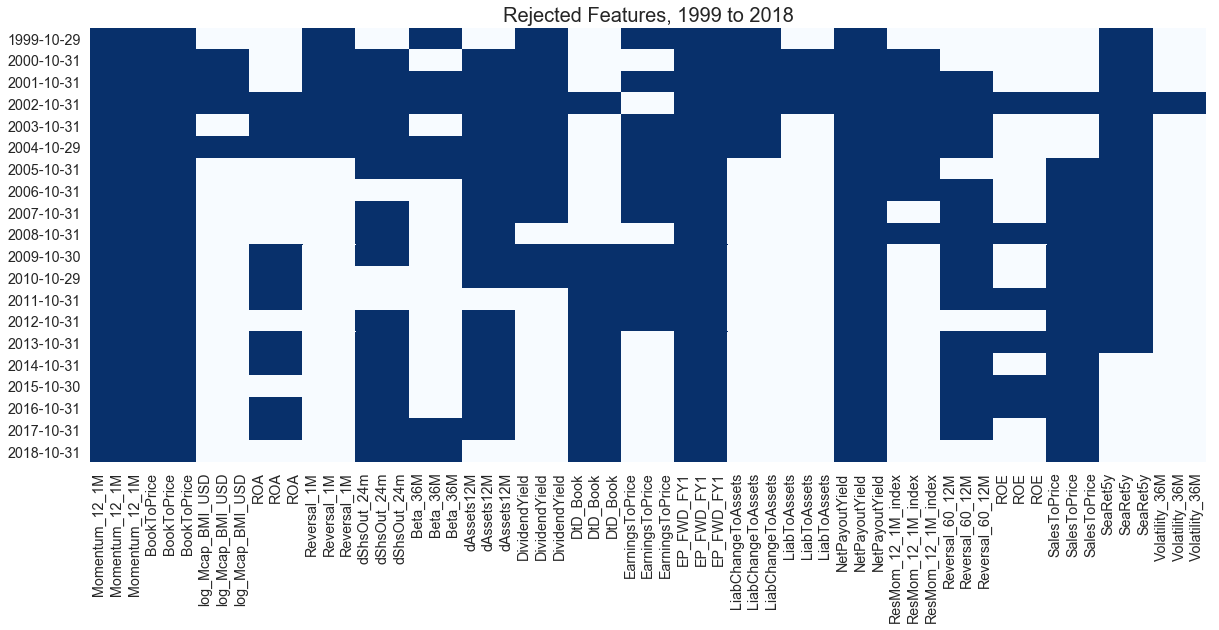

In [58]:
sns.set(font_scale = 1.3)
plt.figure(figsize = (20,8))
sns.heatmap(GL_raw_Summary[GL_raw_Features] != 0, cmap="Blues", cbar=False).set_title(
'Rejected Features, %.0f to %.0f' % (GL_raw_Summary.index[0].year, GL_raw_Summary.index[-1].year), size=20);

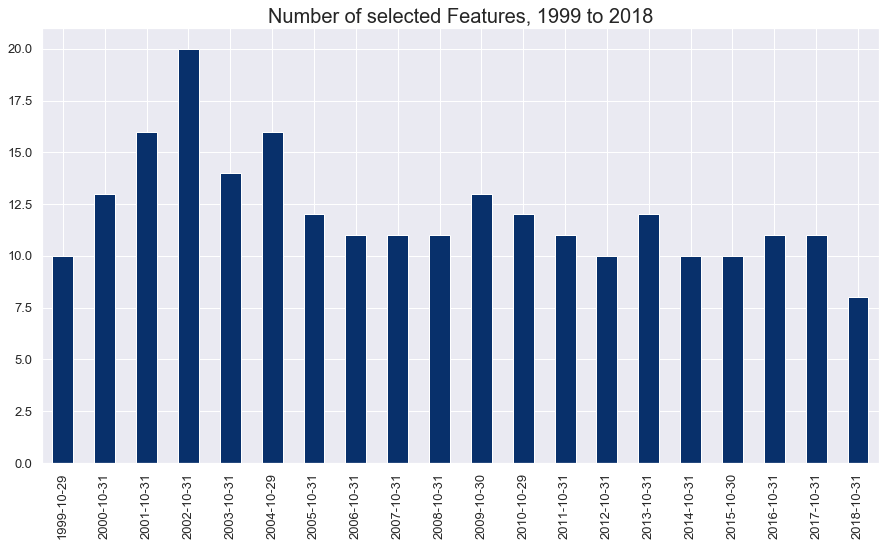

In [59]:
GL_raw_Summary["N"].plot.bar(
figsize=[15,8], 
cmap="Blues_r",  
fontsize=13,
title ="Number of selected Features, %.0f to %.0f" % (GL_raw_Summary.index[0].year, GL_raw_Summary.index[-1].year)).title.set_size(20);

### 5.6 Evaluation

In [60]:
# Create evaluation table
GL_raw_Eval_Data = eval_data(Data=GL_raw_Data, 
                             Predictions=GL_raw_Pre, 
                             Return=Return_v, 
                             Size=Size_v)

# Create Portfolios
GL_raw_Eval_Port, GL_raw_Eval_Port_cRet = portfolios(Eval_Data=GL_raw_Eval_Data, N=10)

# Regress return on prediction and compute statistics
GL_raw_Eval_Reg = linear_eval_reg(Eval_Data=GL_raw_Eval_Data)

# Show statistic
GL_raw_Eval_Reg

,Prediction
Slope,0.77
S.E.,0.12
t-stat,6.31


### cum. Outperformance

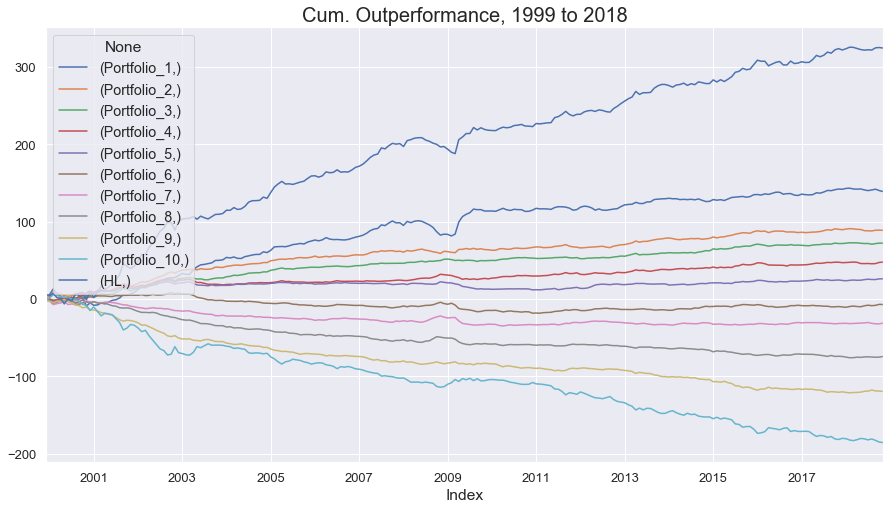

In [61]:
GL_raw_Eval_Port_cRet[GL_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,
title ="Cum. Outperformance, %.0f to %.0f" 
% (GL_raw_Eval_Data.index[0][0].year, GL_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

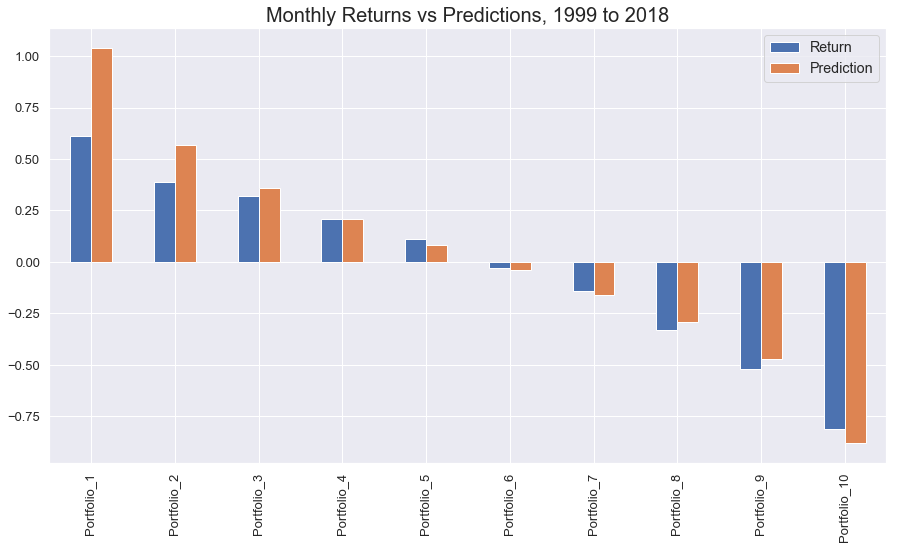

In [62]:
GL_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (GL_raw_Eval_Data.index[0][0].year, GL_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

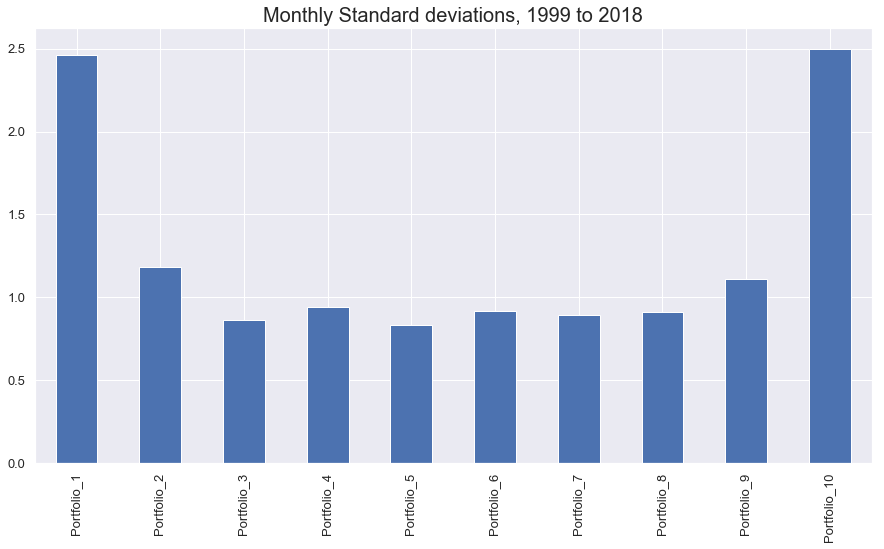

In [63]:
GL_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (GL_raw_Eval_Data.index[0][0].year, GL_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios

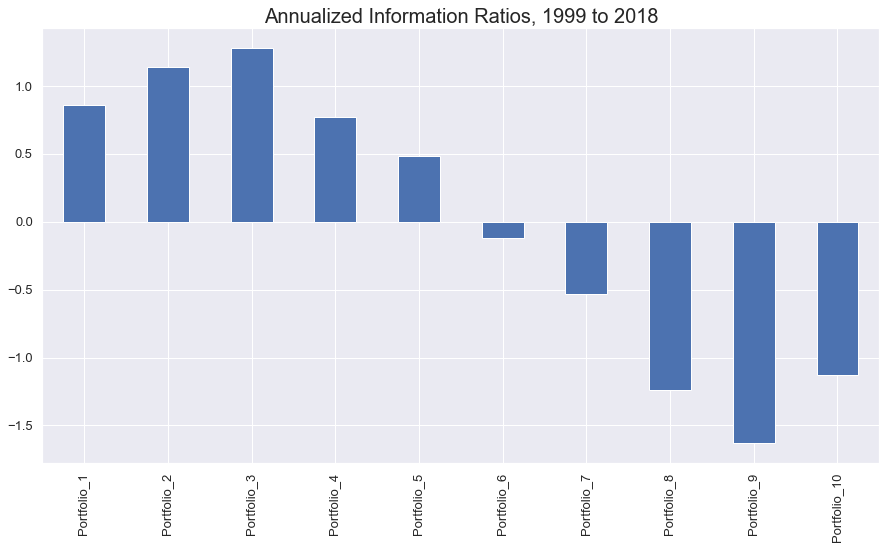

In [64]:
GL_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (GL_raw_Eval_Data.index[0][0].year, GL_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 5.7 Store model

In [65]:
# Store dataframes 
GL_raw_Eval_Port.to_pickle("Gl_sc_Eval_Port")
GL_raw_Eval_Reg.to_pickle("GL_sc_Eval_Reg")
GL_raw_Eval_Port_cRet.to_pickle("GL_sc_Eval_Port_cRet")